# PRCP-1000 — Portuguese Bank Marketing: Term Deposit Subscription Prediction

**Domain:** Finance / Banking
**Dataset:** `bank-additional-full.csv` — direct phone-call marketing campaigns of a Portuguese bank (May 2008 – Nov 2010), 41,188 records, 20 inputs + target `y`.

### Problem Statement
| Task | Description |
|---|---|
| **Task 1** | Prepare a complete data analysis report on the given data |
| **Task 2** | Create a predictive model that tells the marketing team which customer will buy the product (term deposit) |
| **Task 3** | Suggestions to the bank marketing team to make customers buy the product |
| **Extra** | Model Comparison Report & Report on Challenges Faced |

### Notebook Contents
1. Setup & data loading
2. Data understanding & quality checks
3. **Task 1 – Exploratory Data Analysis (EDA)**
4. Data preprocessing & feature engineering
5. **Task 2 – Model building, comparison & tuning**
6. Model evaluation & feature importance
7. **Task 3 – Suggestions to the marketing team**
8. Model Comparison Report
9. Report on Challenges Faced
10. Conclusion

## 1. Setup & Data Loading

In [1]:
import os, json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs("../models", exist_ok=True)

# consistent, colour-blind-checked palette
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
PALETTE = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlecolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})
def save(name):
    plt.savefig(f"{FIG_DIR}/{name}.png")
    plt.show()

In [2]:
df_raw = pd.read_csv("../data/bank-additional-full.csv", sep=";")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Data Understanding & Quality Checks

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [5]:
print("Missing (NaN) values per column:", df_raw.isna().sum().sum())
print("Duplicate rows:", df_raw.duplicated().sum())

cat_cols_raw = df_raw.select_dtypes("object").columns.drop("y")
unknown = (df_raw[cat_cols_raw] == "unknown").sum()
unknown_pct = (unknown / len(df_raw) * 100).round(2)
pd.DataFrame({"unknown_count": unknown, "unknown_%": unknown_pct}).query("unknown_count > 0")

Missing (NaN) values per column: 0
Duplicate rows: 12


,unknown_count,unknown_%
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


In [6]:
print("pdays = 999 (never contacted before):", (df_raw.pdays == 999).sum(),
      f"({(df_raw.pdays == 999).mean()*100:.1f}%)")
print("'default' = yes rows:", (df_raw['default'] == 'yes').sum())

pdays = 999 (never contacted before): 39673 (96.3%)
'default' = yes rows: 3


**Observations**
- No NaN values, but missing information is encoded as the category **`unknown`** — notably `default` (~20.9%), `education` (~4.2%), `housing`/`loan` (2.4%), `job` (0.8%).
- **12 duplicate rows** → removed.
- `pdays = 999` is a sentinel meaning "not previously contacted" (96.3% of rows) — must not be treated as a real number.
- `default = yes` has only 3 rows → almost no information in that level.

In [7]:
df = df_raw.drop_duplicates().reset_index(drop=True)
df["target"] = (df["y"] == "yes").astype(int)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (41176, 22)


## 3. Task 1 — Exploratory Data Analysis

### 3.1 Target distribution

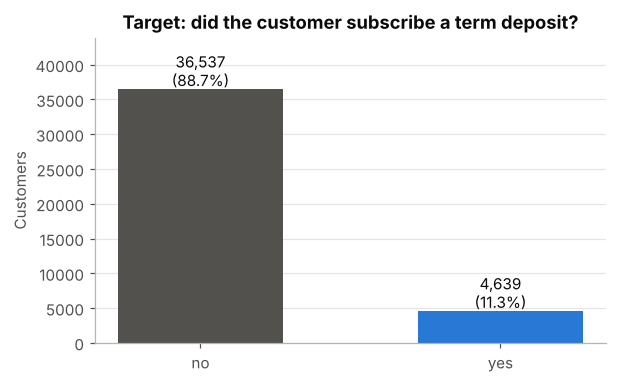

Subscription rate: 11.27%  -> highly imbalanced (~1 : 7.9)


In [8]:
counts = df["y"].value_counts()
fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(counts.index, counts.values, color=[INK2, BLUE], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x()+b.get_width()/2, v+400, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", color=INK)
ax.set_title("Target: did the customer subscribe a term deposit?")
ax.set_ylabel("Customers"); ax.set_ylim(0, counts.max()*1.2); ax.grid(axis="x")
save("01_target_distribution")
print(f"Subscription rate: {df.target.mean()*100:.2f}%  -> highly imbalanced (~1 : 7.9)")

Only **11.27%** of contacted customers subscribed. The data is **highly imbalanced** — a model that always says "no" would already be 88.7% accurate, so accuracy is a misleading metric here. We will use **ROC-AUC, PR-AUC, Recall and F1**.

### 3.2 Numerical features

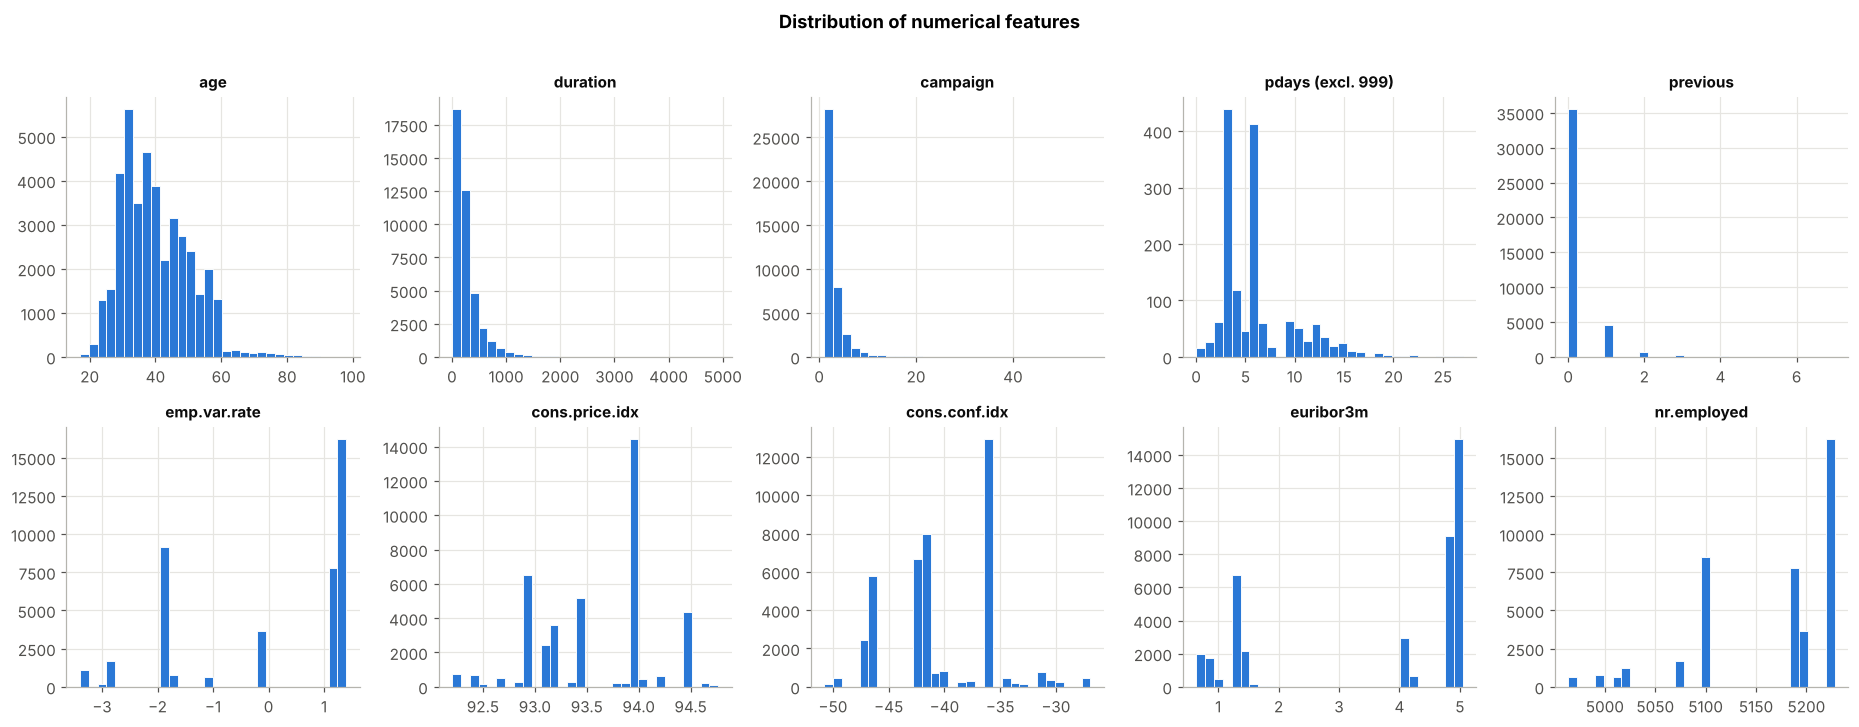

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
skewness,0.78,3.26,4.76,-4.92,3.83,-0.72,-0.23,0.3,-0.71,-1.04


In [9]:
num_cols = ["age", "duration", "campaign", "pdays", "previous",
            "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
fig, axes = plt.subplots(2, 5, figsize=(17, 6.5))
for ax, c in zip(axes.ravel(), num_cols):
    data = df[c] if c != "pdays" else df.loc[df.pdays != 999, c]
    ax.hist(data, bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
    ax.set_title(c + (" (excl. 999)" if c == "pdays" else ""), fontsize=10)
fig.suptitle("Distribution of numerical features", fontweight="bold", y=1.01)
plt.tight_layout(); save("02_numeric_distributions")
df[num_cols].skew().round(2).to_frame("skewness").T

- `duration`, `campaign`, `previous` are strongly **right-skewed** with outliers (campaign up to 56 calls).
- Economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are **multi-modal** — they take a few values tied to time periods.

### 3.3 Subscription rate by categorical features

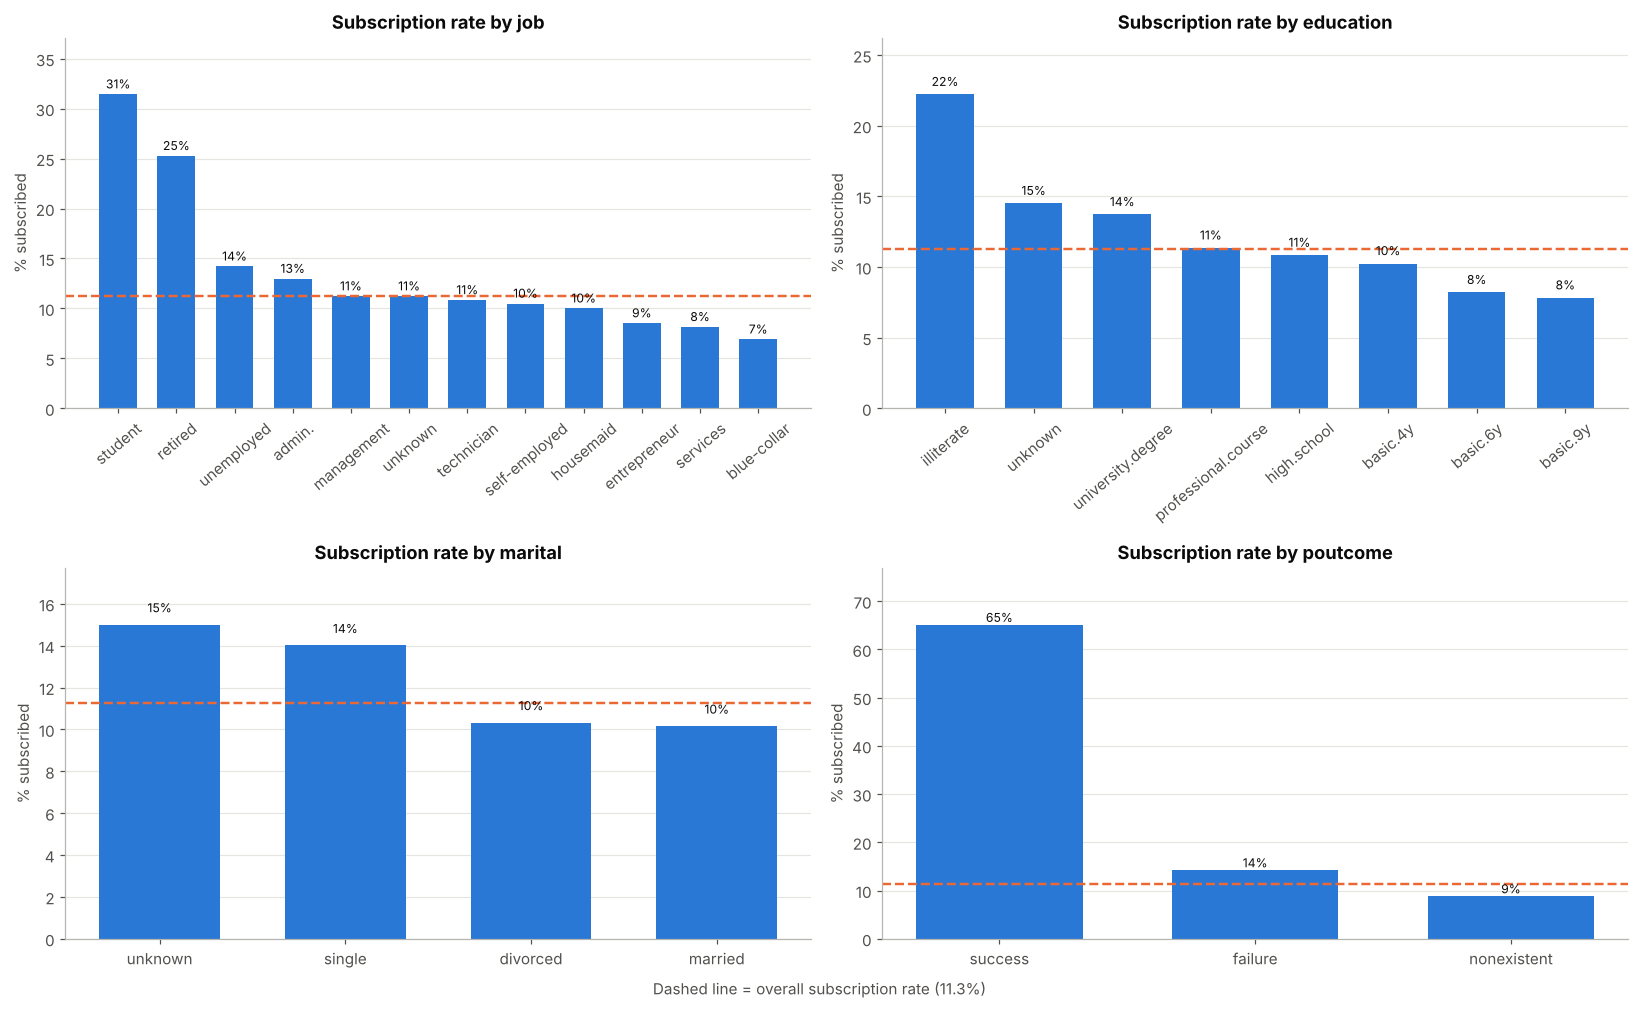

In [10]:
def rate_plot(ax, col, order=None, rotate=False):
    r = df.groupby(col)["target"].agg(["mean", "size"])
    if order is not None: r = r.loc[[o for o in order if o in r.index]]
    else: r = r.sort_values("mean", ascending=False)
    bars = ax.bar(r.index.astype(str), r["mean"]*100, color=BLUE, width=0.65)
    ax.axhline(df.target.mean()*100, color=ORANGE, lw=1.6, ls="--")
    for b, v in zip(bars, r["mean"]*100):
        ax.text(b.get_x()+b.get_width()/2, v+0.6, f"{v:.0f}%", ha="center", fontsize=8, color=INK)
    ax.set_title(f"Subscription rate by {col}"); ax.set_ylabel("% subscribed"); ax.grid(axis="x")
    ax.set_ylim(0, r["mean"].max()*100*1.18)
    if rotate: ax.tick_params(axis="x", rotation=40)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
rate_plot(axes[0,0], "job", rotate=True)
rate_plot(axes[0,1], "education", rotate=True)
rate_plot(axes[1,0], "marital")
rate_plot(axes[1,1], "poutcome")
fig.text(0.5, -0.01, "Dashed line = overall subscription rate (11.3%)", ha="center", color=INK2)
plt.tight_layout(); save("03_rate_by_profile")

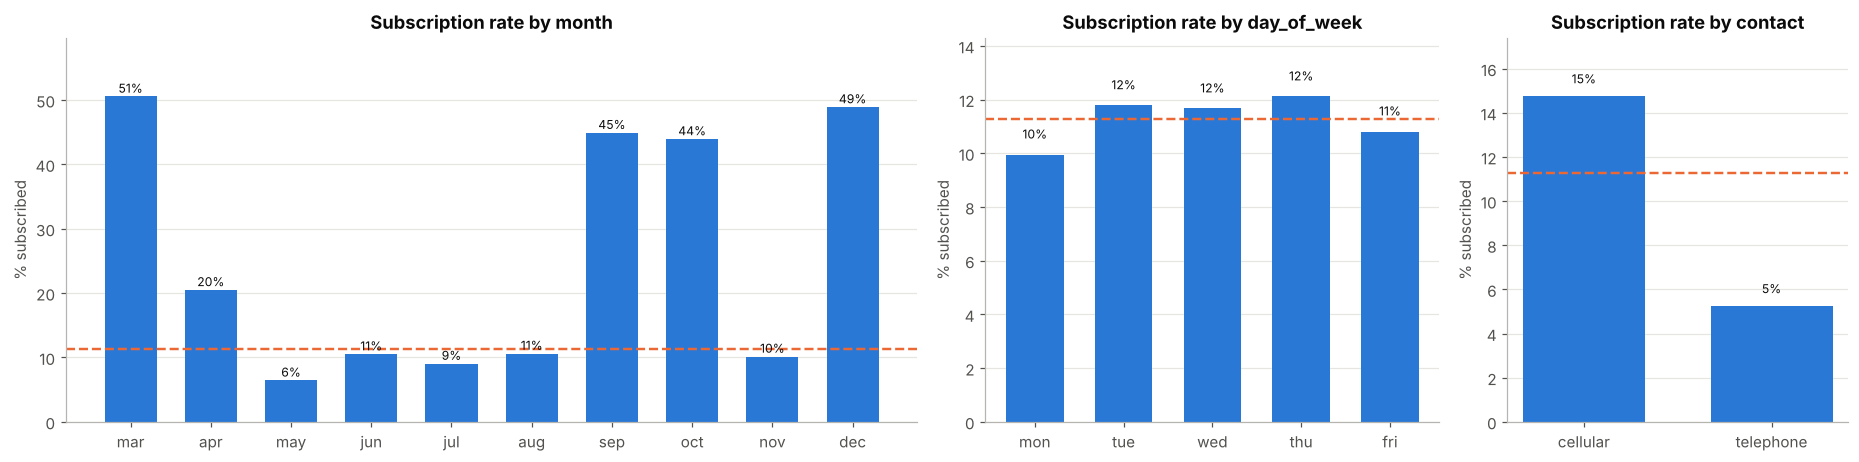

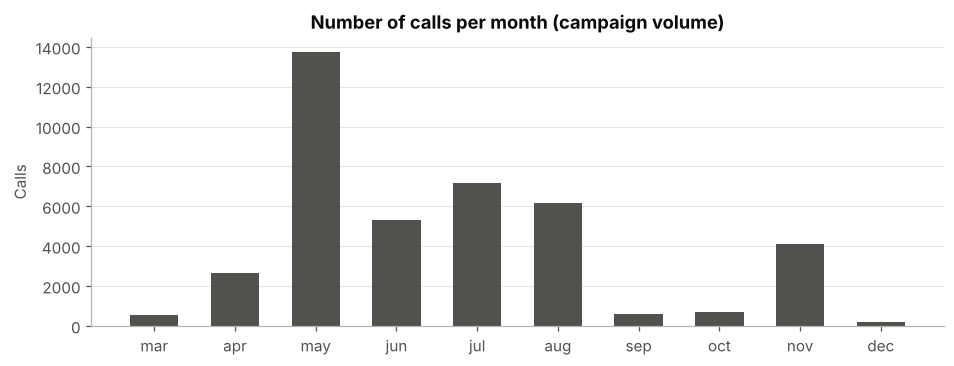

In [11]:
months = ["mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
days = ["mon","tue","wed","thu","fri"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={"width_ratios": [3, 1.6, 1.2]})
rate_plot(axes[0], "month", order=months)
rate_plot(axes[1], "day_of_week", order=days)
rate_plot(axes[2], "contact")
plt.tight_layout(); save("04_rate_by_timing_channel")

vol = df["month"].value_counts().reindex(months)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(vol.index, vol.values, color=INK2, width=0.6)
ax.set_title("Number of calls per month (campaign volume)"); ax.set_ylabel("Calls"); ax.grid(axis="x")
save("05_calls_per_month")

**Key findings**
- **Job:** students (31%) and retired (25%) subscribe the most; blue-collar (7%) and services (8%) the least.
- **poutcome:** customers whose **previous campaign was a success subscribe 65%** of the time — 7× the average.
- **Month:** March, September, October and December convert at **44–50%**, but these months had very few calls. **May** had the most calls (13.7k) but the **lowest rate (6.4%)** → volume ≠ results.
- **Contact:** cellular (14.7%) converts ~3× better than telephone (5.2%).
- Day of week has a small effect (Mon 10% vs Thu 12%).

### 3.4 Age, campaign intensity and previous contact

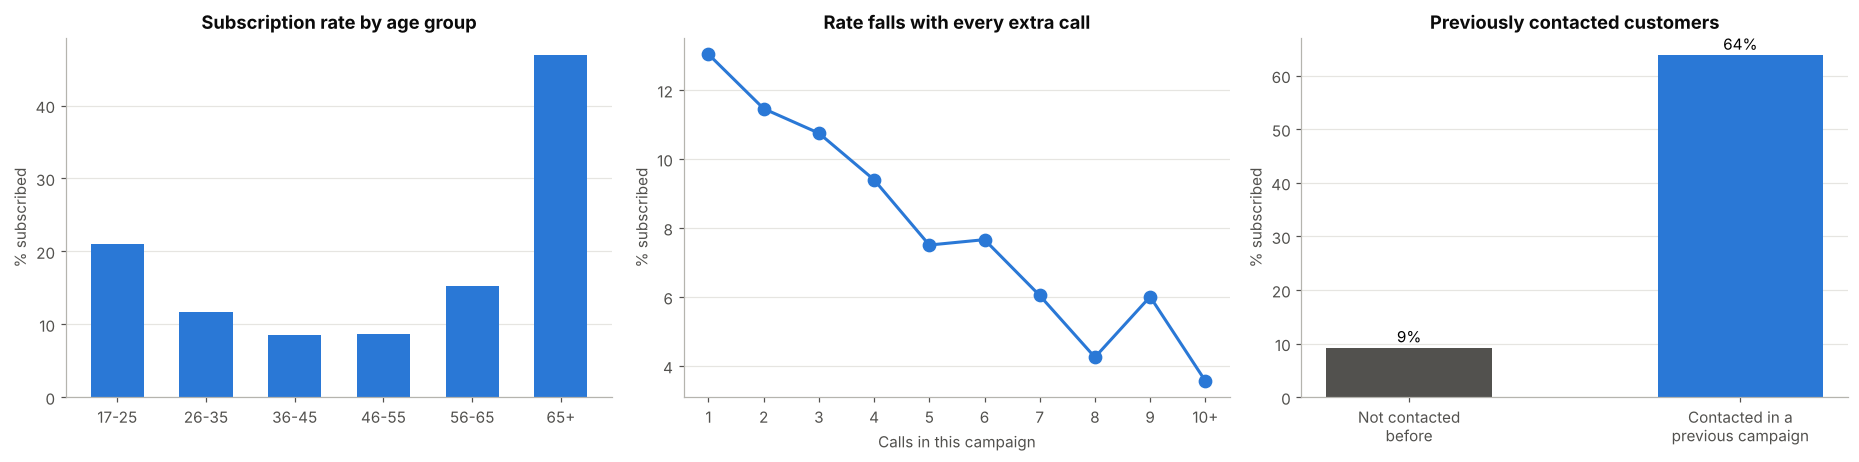

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
ag = df.groupby(pd.cut(df.age, [16,25,35,45,55,65,100]))["target"].mean()*100
axes[0].bar(["17-25","26-35","36-45","46-55","56-65","65+"], ag.values, color=BLUE, width=0.6)
axes[0].set_title("Subscription rate by age group"); axes[0].set_ylabel("% subscribed")

cp = df.groupby(df.campaign.clip(upper=10))["target"].mean()*100
axes[1].plot(cp.index, cp.values, color=BLUE, lw=2, marker="o", ms=8)
axes[1].set_xticks(range(1, 11)); axes[1].set_xticklabels([str(i) for i in range(1,10)] + ["10+"])
axes[1].set_title("Rate falls with every extra call"); axes[1].set_xlabel("Calls in this campaign"); axes[1].set_ylabel("% subscribed")

pc = df.groupby(df.pdays != 999)["target"].mean()*100
axes[2].bar(["Not contacted\nbefore", "Contacted in a\nprevious campaign"], pc.values, color=[INK2, BLUE], width=0.5)
for i, v in enumerate(pc.values): axes[2].text(i, v+1, f"{v:.0f}%", ha="center")
axes[2].set_title("Previously contacted customers"); axes[2].set_ylabel("% subscribed")
for a in axes: a.grid(axis="x")
plt.tight_layout(); save("06_age_campaign_previous")

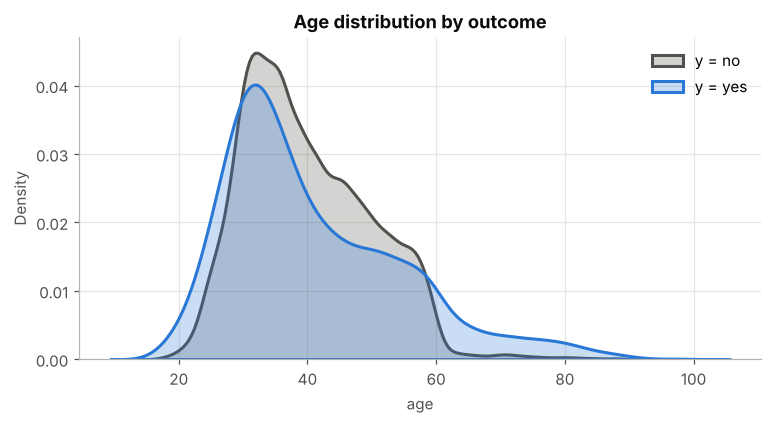

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for lab, col in [("no", INK2), ("yes", BLUE)]:
    sns.kdeplot(df.loc[df.y == lab, "age"], ax=ax, fill=True, alpha=0.25, color=col, label=f"y = {lab}", lw=2)
ax.set_title("Age distribution by outcome"); ax.legend()
save("07_age_kde")

- **U-shaped age effect:** ≤25 (21%) and 65+ (47%) subscribe far more than the 36–55 group (~8.5%).
- **Over-calling hurts:** 13% convert on the 1st call, only ~4% by the 8th.
- Customers **contacted in a previous campaign convert at 64%** vs 9% for new ones.

### 3.5 Socio-economic context

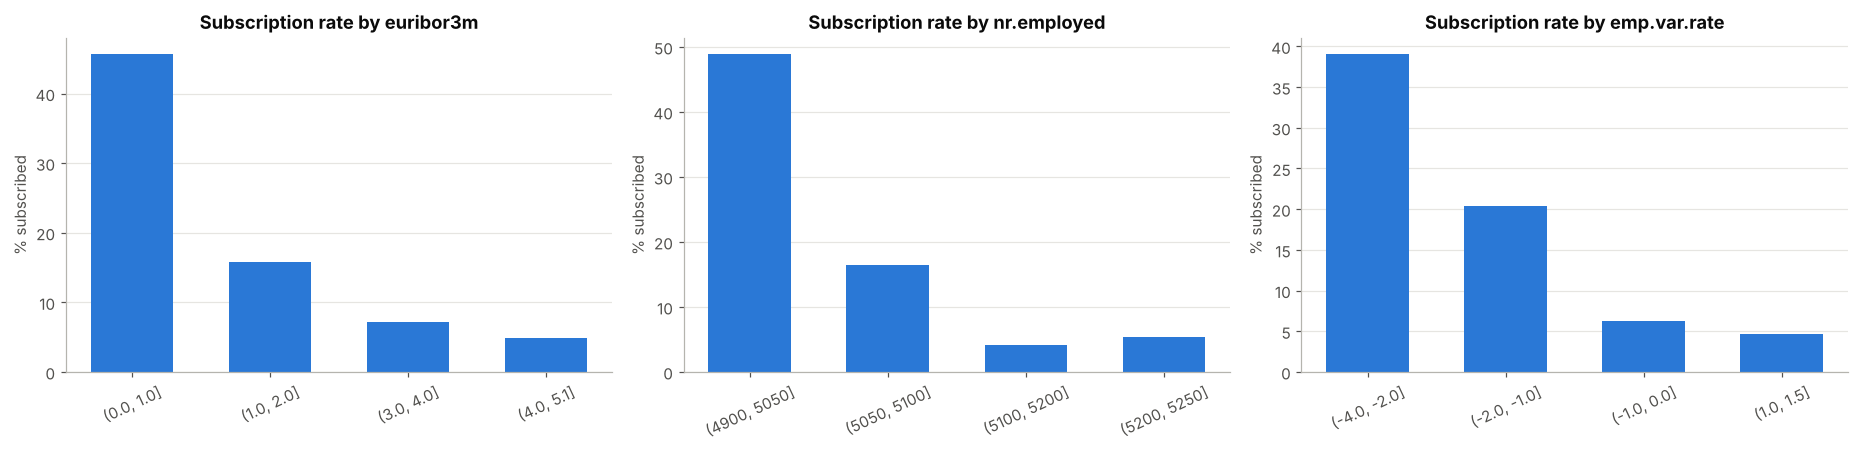

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c, bins in [(axes[0], "euribor3m", [0,1,2,3,4,5.1]),
                    (axes[1], "nr.employed", [4900,5050,5100,5200,5250]),
                    (axes[2], "emp.var.rate", [-4,-2,-1,0,1,1.5])]:
    r = df.groupby(pd.cut(df[c], bins))["target"].mean()*100
    r = r.dropna()
    ax.bar([str(i) for i in r.index], r.values, color=BLUE, width=0.6)
    ax.set_title(f"Subscription rate by {c}"); ax.set_ylabel("% subscribed"); ax.grid(axis="x")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); save("08_economic_context")

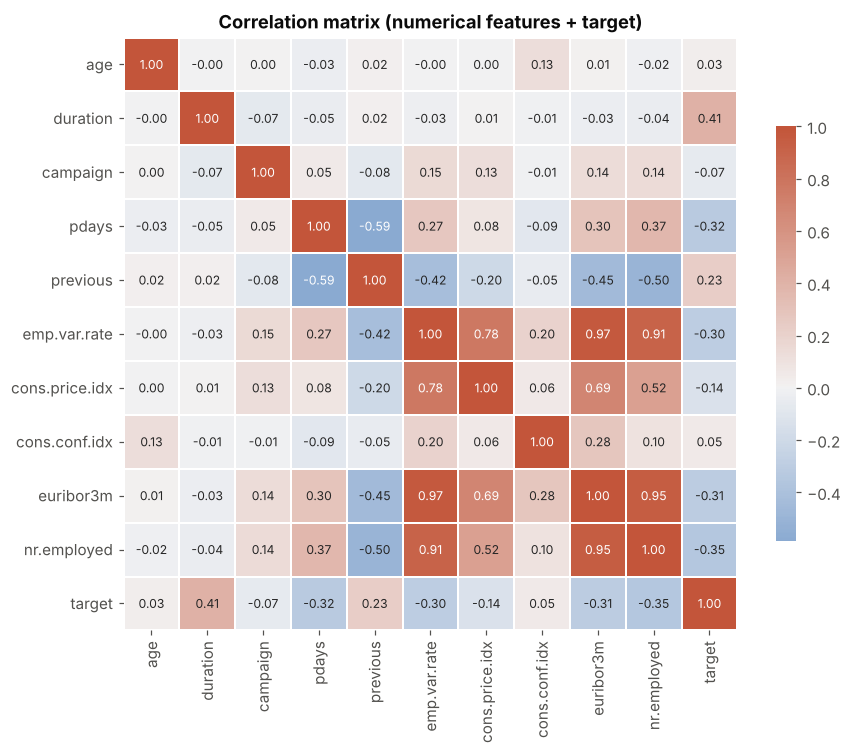

,corr_with_target
duration,0.405
nr.employed,-0.355
pdays,-0.325
euribor3m,-0.308
emp.var.rate,-0.298
previous,0.230
cons.price.idx,-0.136
campaign,-0.066
cons.conf.idx,0.055
age,0.030


In [15]:
corr = df[num_cols + ["target"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 20, as_cmap=True), center=0,
            linewidths=1, linecolor="white", cbar_kws={"shrink": .7}, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix (numerical features + target)")
save("09_correlation_heatmap")
corr["target"].drop("target").sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_target")

- When **interest rates (euribor3m) are low (<1%)** and employment is shrinking, subscription jumps to **~46%**; at euribor > 4% it is under 5%. Macroeconomic timing matters a lot.
- `emp.var.rate`, `euribor3m` and `nr.employed` are **highly inter-correlated (0.90–0.97)** → multicollinearity (handled by regularisation / tree models).
- `duration` has the strongest correlation with the target (0.41) — but it is a **leakage** variable (see below).

### 3.6 The `duration` leakage problem

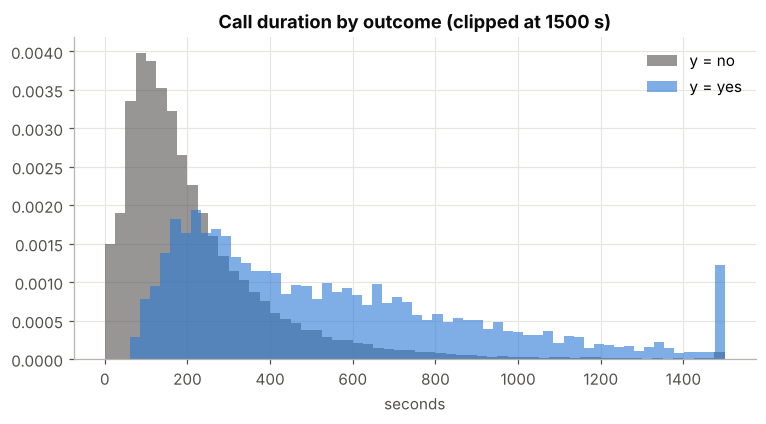

y
no     164.0
yes    449.0
Name: median duration (s), dtype: float64


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for lab, col in [("no", INK2), ("yes", BLUE)]:
    ax.hist(df.loc[df.y == lab, "duration"].clip(upper=1500), bins=60, alpha=0.6, color=col, label=f"y = {lab}", density=True)
ax.set_title("Call duration by outcome (clipped at 1500 s)"); ax.set_xlabel("seconds"); ax.legend()
save("10_duration_leakage")
print(df.groupby("y")["duration"].median().rename("median duration (s)"))

Subscribers' calls last ~**449 s** (median) vs **164 s** for non-subscribers. But duration is only known **after** the call ends — when the outcome is already known. As instructed in the problem statement, `duration` is **dropped** from the realistic model and used only for a benchmark.

### 3.7 EDA Summary (Task 1)
| Area | Insight |
|---|---|
| Target | 11.3% subscribe → imbalanced |
| Best segments | Students, retired, age 65+ / ≤25, previous-campaign success (65%), previously contacted (64%) |
| Channel | Cellular converts 3× better than landline |
| Timing | Mar/Sep/Oct/Dec high-converting but under-used; May over-used and worst |
| Effort | Conversion drops steadily after the 1st–3rd call |
| Macro | Low euribor / low employment → much higher subscription |
| Data quality | `unknown` levels, 12 duplicates, `pdays=999` sentinel, skewed `campaign`, collinear macro features, leaky `duration` |

## 4. Data Preprocessing & Feature Engineering

In [17]:
NUMERIC_COLS = ["age", "campaign", "pdays", "previous", "prev_contacted",
                "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CATEGORICAL_COLS = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome", "age_group"]

def add_features(data):
    """Same logic as src/bank_features.py (used by the Flask app)."""
    out = data.copy()
    out["prev_contacted"] = (out["pdays"] != 999).astype(int)      # sentinel -> flag
    out["pdays"] = out["pdays"].replace(999, -1)
    out["campaign"] = out["campaign"].clip(upper=15)                # cap outliers
    out["age_group"] = pd.cut(out["age"], [0,25,35,45,55,65,120],
                              labels=["<=25","26-35","36-45","46-55","56-65","65+"]).astype(str)
    out = out.drop(columns=[c for c in ["duration", "y", "target"] if c in out.columns])
    return out[NUMERIC_COLS + CATEGORICAL_COLS]

X = add_features(df)
y = df["target"]
print("Feature matrix:", X.shape)
X.head()

Feature matrix: (41176, 21)


,age,campaign,pdays,previous,prev_contacted,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,age_group
0,56,1,-1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,56-65
1,57,1,-1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,56-65
2,37,1,-1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,no,yes,no,telephone,may,mon,nonexistent,36-45
3,40,1,-1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,36-45
4,56,1,-1,0,0,1.1,93.994,-36.4,4.857,5191.0,...,married,high.school,no,no,yes,telephone,may,mon,nonexistent,56-65


**Decisions**
- `unknown` is kept as its **own category** (it carries signal: e.g. `default=unknown` converts at 5% vs 13% for `no`). Dropping 26% of rows or imputing the mode would lose or distort information.
- `duration` dropped (leakage). `pdays` → `prev_contacted` flag + sentinel. `campaign` capped at 15. New `age_group` feature.
- One-Hot Encoding for categoricals, StandardScaler for numerics — wrapped in a **Pipeline** so there is no train/test leakage.
- **Stratified 80/20 split** keeps the 11.3% ratio in both sets.

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"positive rate {y_train.mean():.4f}")
print("Test :", X_test.shape,  f"positive rate {y_test.mean():.4f}")

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
])

Train: (32940, 21) positive rate 0.1127
Test : (8236, 21) positive rate 0.1127


## 5. Task 2 — Model Building & Comparison

Seven algorithms are compared with **5-fold stratified cross-validation** on the training set. Class imbalance is handled with `class_weight="balanced"` / `scale_pos_weight` (and SMOTE is tested separately). Primary metric: **ROC-AUC**; secondary: PR-AUC, Recall, F1.

In [19]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    "Logistic Reg. + SMOTE": "smote",
    "KNN": KNeighborsClassifier(n_neighbors=25, weights="distance"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=10, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.08, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="auc", n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(n_estimators=400, num_leaves=31, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", verbose=-1, random_state=RANDOM_STATE),
}

def make_pipe(name, est):
    if est == "smote":
        return ImbPipeline([("prep", preprocessor), ("smote", SMOTE(random_state=RANDOM_STATE)),
                            ("model", LogisticRegression(max_iter=2000, C=0.5))])
    return Pipeline([("prep", preprocessor), ("model", est)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall",
           "precision": "precision", "f1": "f1", "accuracy": "accuracy"}
rows = []
for name, est in models.items():
    t0 = time.time()
    res = cross_validate(make_pipe(name, est), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"Model": name, **{k: res[f"test_{k}"].mean() for k in scoring},
                 "ROC-AUC std": res["test_roc_auc"].std(), "Time (s)": time.time() - t0})
    print(f"{name:24s} ROC-AUC={rows[-1]['roc_auc']:.4f}  recall={rows[-1]['recall']:.3f}  ({rows[-1]['Time (s)']:.0f}s)")

cv_results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
cv_results.round(4)

Logistic Regression      ROC-AUC=0.7903  recall=0.624  (2s)


Logistic Reg. + SMOTE    ROC-AUC=0.7872  recall=0.625  (3s)


KNN                      ROC-AUC=0.7604  recall=0.257  (4s)


Decision Tree            ROC-AUC=0.7798  recall=0.604  (1s)


Random Forest            ROC-AUC=0.7996  recall=0.606  (12s)


Gradient Boosting        ROC-AUC=0.7968  recall=0.255  (37s)


XGBoost                  ROC-AUC=0.7982  recall=0.629  (3s)


LightGBM                 ROC-AUC=0.7977  recall=0.620  (3s)


,Model,roc_auc,pr_auc,recall,precision,f1,accuracy,ROC-AUC std,Time (s)
0,Random Forest,0.7996,0.4682,0.6058,0.4066,0.4865,0.8559,0.0094,11.8649
1,XGBoost,0.7982,0.4640,0.6292,0.3698,0.4658,0.8373,0.0073,3.0800
2,LightGBM,0.7977,0.4693,0.6198,0.3830,0.4734,0.8446,0.0079,3.3685
3,Gradient Boosting,0.7968,0.4642,0.2552,0.6583,0.3678,0.9012,0.0075,36.7209
4,Logistic Regression,0.7903,0.4453,0.6244,0.3530,0.4510,0.8287,0.0073,1.6567
5,Logistic Reg. + SMOTE,0.7872,0.4433,0.6246,0.3425,0.4424,0.8226,0.0081,2.9986
6,Decision Tree,0.7798,0.4172,0.6041,0.3589,0.4475,0.8305,0.0108,0.7537
7,KNN,0.7604,0.3797,0.2573,0.5806,0.3564,0.8954,0.0084,4.2834


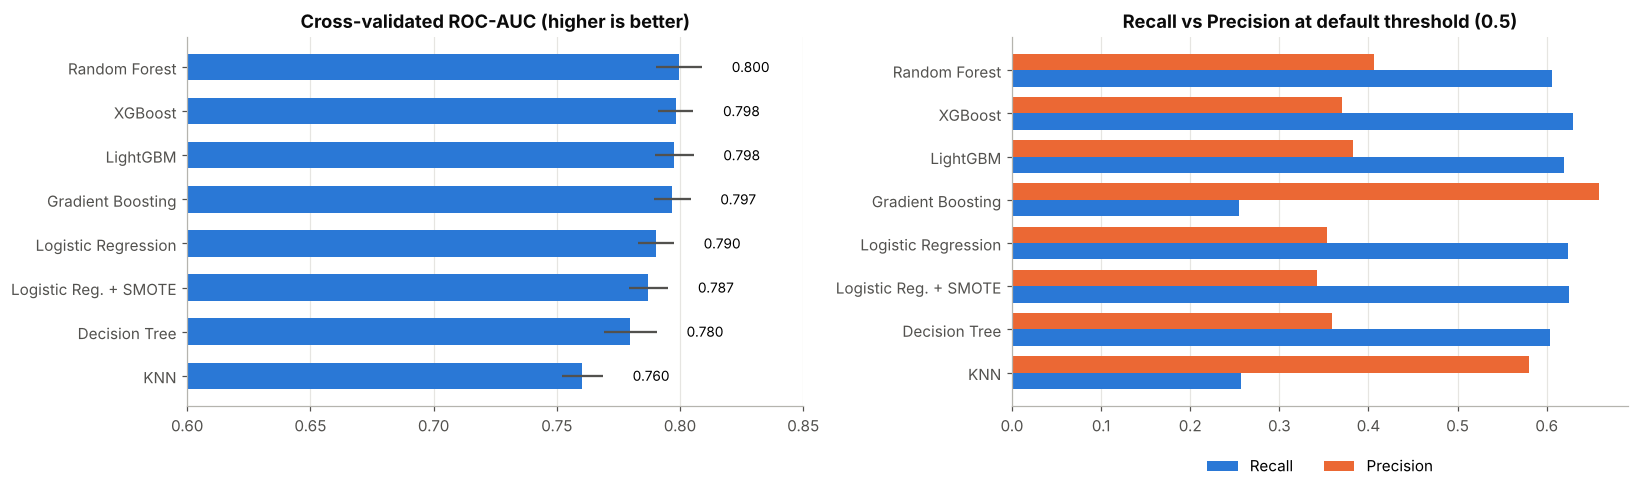

In [20]:
plot_df = cv_results.sort_values("roc_auc")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].barh(plot_df.Model, plot_df.roc_auc, color=BLUE, height=0.6, xerr=plot_df["ROC-AUC std"], ecolor=INK2)
for i, v in enumerate(plot_df.roc_auc + plot_df["ROC-AUC std"]): axes[0].text(v+0.012, i, f"{plot_df.roc_auc.iloc[i]:.3f}", va="center", fontsize=9)
axes[0].set_xlim(0.6, 0.85); axes[0].set_title("Cross-validated ROC-AUC (higher is better)"); axes[0].grid(axis="y")

x = np.arange(len(plot_df)); w = 0.38
axes[1].barh(x - w/2, plot_df.recall, height=w, color=BLUE, label="Recall")
axes[1].barh(x + w/2, plot_df.precision, height=w, color=ORANGE, label="Precision")
axes[1].set_yticks(x); axes[1].set_yticklabels(plot_df.Model)
axes[1].set_title("Recall vs Precision at default threshold (0.5)"); axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); axes[1].grid(axis="y")
plt.tight_layout(); save("11_model_comparison_cv")

Boosting models (**LightGBM, XGBoost, Gradient Boosting**) and Random Forest lead on ROC-AUC. Plain Gradient Boosting / KNN (no class weighting) have high precision but very low recall — they miss most buyers. We take the top boosting model forward for hyper-parameter tuning.

### 5.1 Hyper-parameter tuning of the best candidates

In [21]:
search_spaces = {
    "LightGBM": (LGBMClassifier(class_weight="balanced", subsample_freq=1, verbose=-1, random_state=RANDOM_STATE), {
        "model__n_estimators": [300, 500, 700, 900],
        "model__learning_rate": [0.01, 0.02, 0.03, 0.05],
        "model__num_leaves": [15, 31, 47, 63],
        "model__min_child_samples": [20, 50, 100, 200],
        "model__subsample": [0.7, 0.8, 0.9],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__reg_lambda": [0, 1, 5, 10]}),
    "XGBoost": (XGBClassifier(scale_pos_weight=spw, eval_metric="auc", n_jobs=-1, random_state=RANDOM_STATE), {
        "model__n_estimators": [300, 500, 700],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "model__max_depth": [3, 4, 5, 6],
        "model__min_child_weight": [1, 5, 10],
        "model__subsample": [0.7, 0.8, 0.9],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__reg_lambda": [1, 5, 10]}),
}
tuned = {}
for name, (est, grid) in search_spaces.items():
    rs = RandomizedSearchCV(Pipeline([("prep", preprocessor), ("model", est)]), grid, n_iter=20,
                            scoring="roc_auc", cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_train, y_train)
    tuned[name] = rs
    print(f"{name}: best CV ROC-AUC = {rs.best_score_:.4f}")
    print("   ", {k.replace('model__', ''): v for k, v in rs.best_params_.items()})

best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_pipe = tuned[best_name].best_estimator_
print("\nSelected model:", best_name)

LightGBM: best CV ROC-AUC = 0.7996
    {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 20, 'learning_rate': 0.02, 'colsample_bytree': 0.5}


XGBoost: best CV ROC-AUC = 0.7980
    {'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.5}

Selected model: LightGBM


### 5.2 Decision-threshold optimisation

With 11% positives, the default 0.5 threshold is not optimal. Using **out-of-fold predictions on the training set only**, we pick the threshold that maximises F1 (balance between catching buyers and not wasting calls).

Optimal threshold = 0.686  (OOF precision 0.455, recall 0.561, F1 0.503)


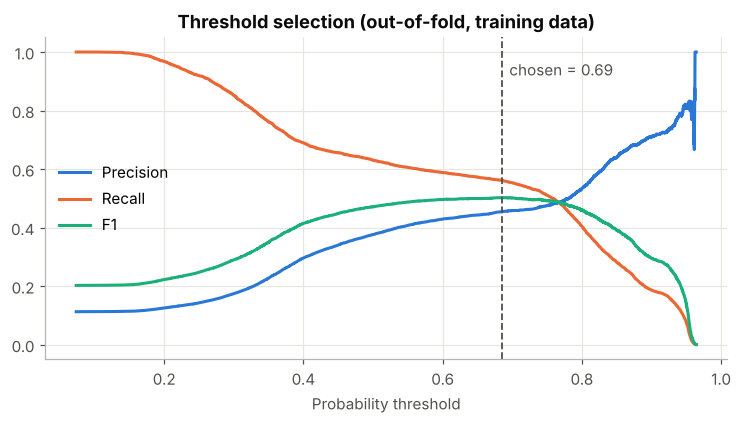

In [22]:
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-12)
best_idx = np.argmax(f1s[:-1])
BEST_THRESHOLD = float(thr[best_idx])
print(f"Optimal threshold = {BEST_THRESHOLD:.3f}  (OOF precision {prec[best_idx]:.3f}, recall {rec[best_idx]:.3f}, F1 {f1s[best_idx]:.3f})")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thr, prec[:-1], color=BLUE, lw=2, label="Precision")
ax.plot(thr, rec[:-1], color=ORANGE, lw=2, label="Recall")
ax.plot(thr, f1s[:-1], color=AQUA, lw=2, label="F1")
ax.axvline(BEST_THRESHOLD, color=INK2, ls="--", lw=1.2)
ax.text(BEST_THRESHOLD+0.01, 0.92, f"chosen = {BEST_THRESHOLD:.2f}", color=INK2)
ax.set_xlabel("Probability threshold"); ax.set_title("Threshold selection (out-of-fold, training data)"); ax.legend()
save("12_threshold_selection")

## 6. Final Evaluation on the Hold-out Test Set

In [23]:
best_pipe.fit(X_train, y_train)
proba = best_pipe.predict_proba(X_test)[:, 1]

def evaluate(name, p, t):
    pred = (p >= t).astype(int)
    return {"Model": name, "Threshold": round(t, 3), "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}

# every baseline model refit on full train and scored on test (default 0.5 threshold) for the comparison report
test_rows = []
for name, est in models.items():
    pipe = make_pipe(name, est).fit(X_train, y_train)
    test_rows.append(evaluate(name, pipe.predict_proba(X_test)[:, 1], 0.5))
for name, rs in tuned.items():
    p = rs.best_estimator_.predict_proba(X_test)[:, 1]
    test_rows.append(evaluate(f"{name} (tuned)", p, 0.5))
test_rows.append(evaluate(f"{best_name} (tuned + threshold)", proba, BEST_THRESHOLD))
test_results = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
test_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LightGBM (tuned + threshold),0.686,0.8827,0.4834,0.5981,0.5347,0.8140,0.4894
1,LightGBM (tuned),0.500,0.8459,0.3908,0.6573,0.4902,0.8140,0.4894
2,Random Forest,0.500,0.8613,0.4231,0.6347,0.5078,0.8129,0.4860
3,XGBoost (tuned),0.500,0.8423,0.3837,0.6595,0.4851,0.8119,0.4842
4,Gradient Boosting,0.500,0.8995,0.6488,0.2349,0.3449,0.8111,0.4789
5,LightGBM,0.500,0.8517,0.4017,0.6455,0.4952,0.8097,0.4898
6,XGBoost,0.500,0.8457,0.3901,0.6562,0.4894,0.8094,0.4770
7,Logistic Regression,0.500,0.8306,0.3603,0.6487,0.4633,0.8009,0.4464
8,Decision Tree,0.500,0.8605,0.4202,0.6272,0.5032,0.7995,0.4565
9,Logistic Reg. + SMOTE,0.500,0.8244,0.3508,0.6562,0.4572,0.7993,0.4449


              precision    recall  f1-score   support

      No (0)      0.947     0.919     0.933      7308
     Yes (1)      0.483     0.598     0.535       928

    accuracy                          0.883      8236
   macro avg      0.715     0.758     0.734      8236
weighted avg      0.895     0.883     0.888      8236



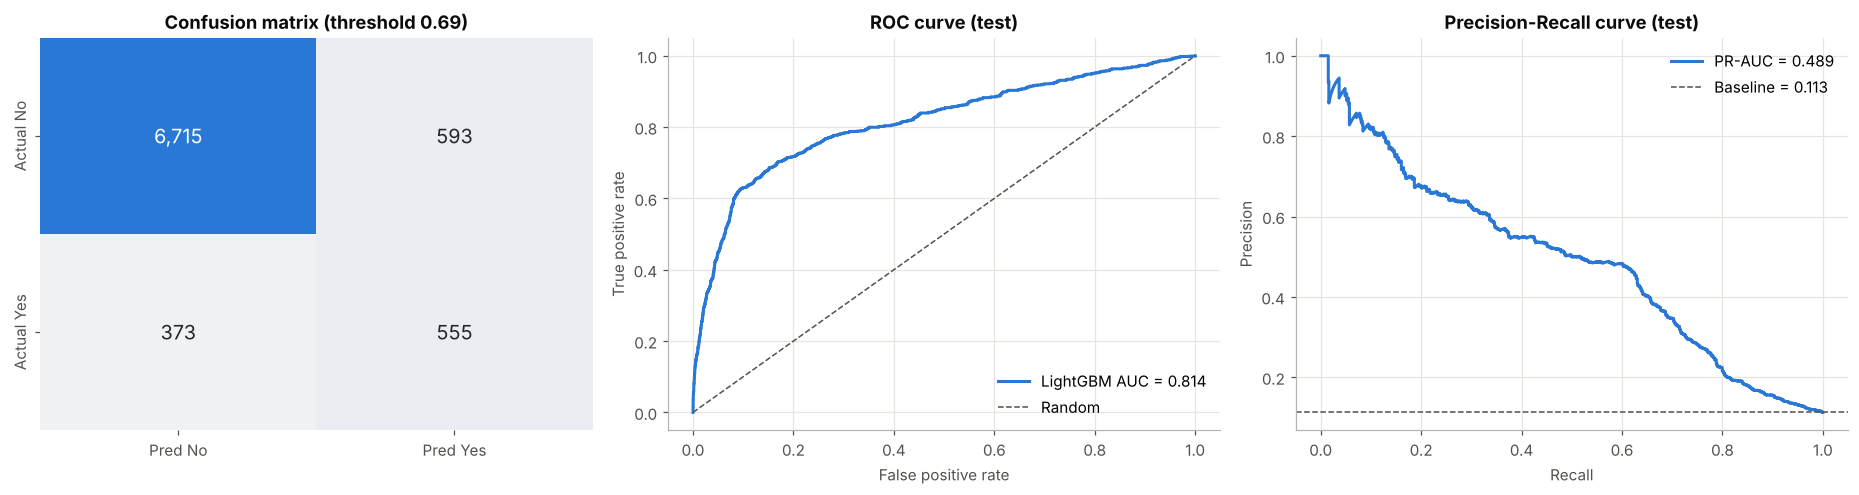

In [24]:
final = evaluate(f"{best_name} (tuned + threshold)", proba, BEST_THRESHOLD)
pred = (proba >= BEST_THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["No (0)", "Yes (1)"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt=",d", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, ax=axes[0],
            xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"], annot_kws={"size": 13})
axes[0].set_title(f"Confusion matrix (threshold {BEST_THRESHOLD:.2f})")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=BLUE, lw=2, label=f"{best_name} AUC = {final['ROC-AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], color=INK2, ls="--", lw=1, label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve (test)"); axes[1].legend(loc="lower right")

p_, r_, _ = precision_recall_curve(y_test, proba)
axes[2].plot(r_, p_, color=BLUE, lw=2, label=f"PR-AUC = {final['PR-AUC']:.3f}")
axes[2].axhline(y_test.mean(), color=INK2, ls="--", lw=1, label=f"Baseline = {y_test.mean():.3f}")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision"); axes[2].set_title("Precision-Recall curve (test)"); axes[2].legend()
plt.tight_layout(); save("13_final_evaluation")

### 6.1 Business view — lift / gains

Conversion rate in model's top-10% list: 52.1%  (vs 11.3% random)


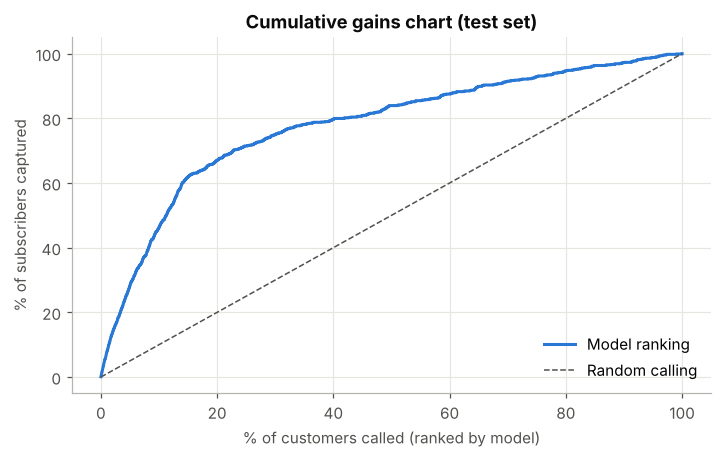

,Top % of customers called,% of all buyers reached,Lift vs random
0,10,46.23,4.62
1,20,66.92,3.35
2,30,74.89,2.50
3,40,79.63,1.99
4,50,83.94,1.68


In [25]:
order = np.argsort(-proba)
cum_pos = np.cumsum(y_test.values[order]) / y_test.sum()
pct = np.arange(1, len(order)+1) / len(order)
lift_tbl = pd.DataFrame({
    "Top % of customers called": [10, 20, 30, 40, 50],
    "% of all buyers reached": [cum_pos[int(len(order)*k/100)-1]*100 for k in [10, 20, 30, 40, 50]]})
lift_tbl["Lift vs random"] = lift_tbl["% of all buyers reached"] / lift_tbl["Top % of customers called"]
top10_rate = y_test.values[order][: int(len(order)*0.1)].mean()
print(f"Conversion rate in model's top-10% list: {top10_rate*100:.1f}%  (vs {y_test.mean()*100:.1f}% random)")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(pct*100, cum_pos*100, color=BLUE, lw=2, label="Model ranking")
ax.plot([0, 100], [0, 100], color=INK2, ls="--", lw=1, label="Random calling")
ax.set_xlabel("% of customers called (ranked by model)"); ax.set_ylabel("% of subscribers captured")
ax.set_title("Cumulative gains chart (test set)"); ax.legend(loc="lower right")
save("14_cumulative_gains")
lift_tbl.round(2)

### 6.2 Feature importance

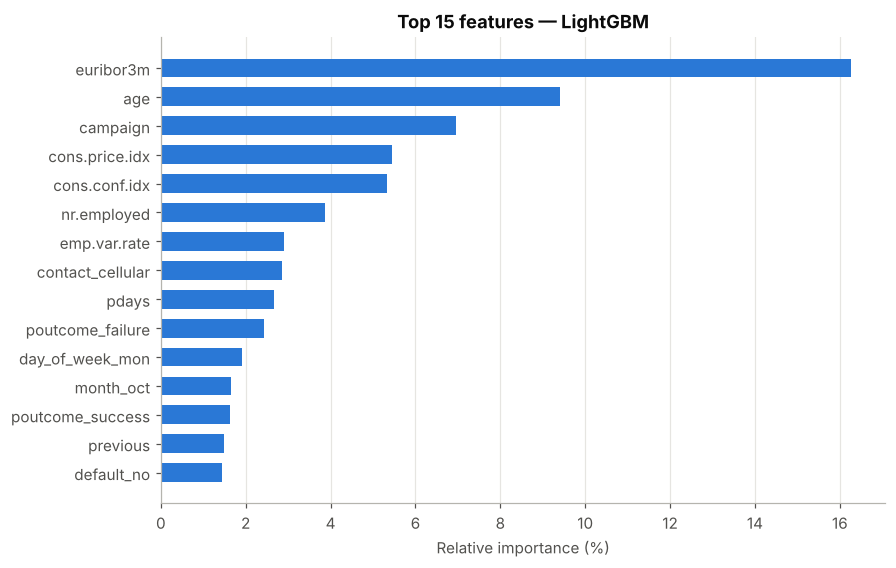

,importance
euribor3m,0.1626
age,0.0940
campaign,0.0695
cons.price.idx,0.0545
cons.conf.idx,0.0533
nr.employed,0.0386
emp.var.rate,0.0290
contact_cellular,0.0286
pdays,0.0267
poutcome_failure,0.0243


In [26]:
feat_names = best_pipe.named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__", 1)[1] for f in feat_names]
imp = pd.Series(best_pipe.named_steps["model"].feature_importances_, index=feat_names)
imp = (imp / imp.sum()).sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(imp.index, imp.values*100, color=BLUE, height=0.65)
ax.set_xlabel("Relative importance (%)"); ax.set_title(f"Top 15 features — {best_name}"); ax.grid(axis="y")
save("15_feature_importance")
imp[::-1].round(4).to_frame("importance")

### 6.3 Benchmark: what if `duration` were allowed?

In [27]:
Xd = X.copy(); Xd["duration"] = df["duration"].values
Xd_tr, Xd_te = Xd.loc[X_train.index], Xd.loc[X_test.index]
prep_d = ColumnTransformer([("num", StandardScaler(), NUMERIC_COLS + ["duration"]),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS)])
bench = Pipeline([("prep", prep_d), ("model", LGBMClassifier(n_estimators=400, learning_rate=0.03, class_weight="balanced", verbose=-1, random_state=RANDOM_STATE))])
bench.fit(Xd_tr, y_train)
bench_auc = roc_auc_score(y_test, bench.predict_proba(Xd_te)[:, 1])
print(f"Benchmark ROC-AUC WITH duration : {bench_auc:.4f}  (not usable in practice - leakage)")
print(f"Realistic ROC-AUC WITHOUT duration: {final['ROC-AUC']:.4f}")

Benchmark ROC-AUC WITH duration : 0.9508  (not usable in practice - leakage)
Realistic ROC-AUC WITHOUT duration: 0.8140


### 6.4 Save the production model

In [28]:
artifact = {"pipeline": best_pipe, "threshold": BEST_THRESHOLD, "model_name": best_name,
            "numeric_cols": NUMERIC_COLS, "categorical_cols": CATEGORICAL_COLS,
            "test_metrics": {k: (round(v, 4) if isinstance(v, float) else v) for k, v in final.items()}}
joblib.dump(artifact, "../models/best_model.pkl")

cv_results.round(4).to_csv("../reports/model_comparison_cv.csv", index=False)
test_results.round(4).to_csv("../reports/model_comparison_test.csv", index=False)
metrics = {"final": artifact["test_metrics"], "best_params": {k.replace("model__", ""): v for k, v in tuned[best_name].best_params_.items()},
           "tuned_cv_auc": {k: round(v.best_score_, 4) for k, v in tuned.items()},
           "benchmark_auc_with_duration": round(bench_auc, 4), "top10_conversion": round(top10_rate, 4),
           "lift_table": lift_tbl.round(3).to_dict(orient="list"),
           "top_features": imp[::-1].round(4).to_dict()}
json.dump(metrics, open("../reports/metrics.json", "w"), indent=2, default=str)
print("Saved models/best_model.pkl and reports/*.csv / metrics.json")

Saved models/best_model.pkl and reports/*.csv / metrics.json


### 6.5 Predicting for a new customer

In [29]:
new_customer = pd.DataFrame([{
    "age": 67, "job": "retired", "marital": "married", "education": "basic.4y", "default": "no",
    "housing": "no", "loan": "no", "contact": "cellular", "month": "oct", "day_of_week": "thu",
    "duration": 0, "campaign": 1, "pdays": 6, "previous": 1, "poutcome": "success",
    "emp.var.rate": -3.4, "cons.price.idx": 92.431, "cons.conf.idx": -26.9, "euribor3m": 0.73, "nr.employed": 5017.5}])
p = best_pipe.predict_proba(add_features(new_customer))[0, 1]
print(f"Purchase probability: {p:.1%} ->", "WILL BUY - call this customer" if p >= BEST_THRESHOLD else "unlikely to buy")

Purchase probability: 94.5% -> WILL BUY - call this customer


## 7. Task 3 — Suggestions to the Bank Marketing Team

Based on the EDA and the model, these actions will raise term-deposit sales while **reducing the number of calls**:

| # | Recommendation | Evidence from the data |
|---|---|---|
| 1 | **Call model-ranked leads first.** Score every customer before a campaign and call the top 20–30%. | Top 10% of the model's list converts at **52%** (4.6× random); top 30% captures **75%** of all buyers. |
| 2 | **Re-target past responders.** Build a priority list of customers whose previous campaign was a *success* or who were contacted before. | `poutcome=success` → **65%**; previously contacted → **64%** vs 9% for new customers. |
| 3 | **Focus on high-propensity segments:** students, retired, age ≤25 and 65+. Design products for them (senior savings plans, student/first-job deposits). | Students 31%, retired 25%, 65+ 47%, ≤25 21% vs 11% average. |
| 4 | **Limit calls per customer to ~3.** After 3 unsuccessful attempts, move to email/SMS or pause. | Conversion falls from 13% (1st call) to ~4% (8th call); repeat calls waste agent time and annoy customers. |
| 5 | **Prefer mobile (cellular) contact** and keep customers' mobile numbers updated. | Cellular 14.7% vs landline 5.2%. |
| 6 | **Re-balance the campaign calendar.** Spread effort into Mar, Apr, Sep, Oct, Dec instead of concentrating it in May. | Mar/Sep/Oct/Dec convert at 44–50% with few calls; May had 33% of calls but only 6.4% conversion. |
| 7 | **Time campaigns to the economy.** Push term deposits harder when Euribor rates fall / economic uncertainty rises (customers seek safe savings). | euribor3m < 1% → ~46% conversion vs < 5% when > 4%; euribor3m is the model's #1 feature. |
| 8 | **Train agents for longer, quality conversations.** Use scripts that engage the customer rather than rushing. | Subscribers' calls last ~449 s vs 164 s for non-subscribers. |
| 9 | **Fix data gaps.** Capture `default`, `education`, `housing/loan` status — 21% of `default` is "unknown". | Better data → better targeting; `default=unknown` customers convert at only 5%. |
| 10 | **Measure & retrain.** Run an A/B test (model-ranked list vs current process), track conversion per call, retrain the model each quarter. | Macro conditions shift over time; the model must stay current. |

## 8. Model Comparison Report

**Test-set results (hold-out 20%, 8,236 customers, 928 buyers)**

| Model | ROC-AUC | PR-AUC | Recall | Precision | F1 | Accuracy |
|---|---|---|---|---|---|---|
| **LightGBM (tuned + threshold 0.69)** | **0.814** | **0.489** | 0.598 | 0.483 | **0.535** | 0.883 |
| LightGBM (tuned, thr 0.5) | 0.814 | 0.489 | 0.657 | 0.391 | 0.490 | 0.846 |
| Random Forest | 0.813 | 0.486 | 0.635 | 0.423 | 0.508 | 0.861 |
| XGBoost (tuned) | 0.812 | 0.484 | 0.660 | 0.384 | 0.485 | 0.842 |
| Gradient Boosting | 0.811 | 0.479 | 0.235 | 0.649 | 0.345 | 0.900 |
| LightGBM (default) | 0.810 | 0.490 | 0.646 | 0.402 | 0.495 | 0.852 |
| XGBoost (default) | 0.809 | 0.477 | 0.656 | 0.390 | 0.489 | 0.846 |
| Logistic Regression | 0.801 | 0.446 | 0.649 | 0.360 | 0.463 | 0.831 |
| Decision Tree | 0.800 | 0.457 | 0.627 | 0.420 | 0.503 | 0.861 |
| Logistic Reg. + SMOTE | 0.799 | 0.445 | 0.656 | 0.351 | 0.457 | 0.824 |
| KNN | 0.762 | 0.383 | 0.266 | 0.587 | 0.366 | 0.896 |

**Analysis**
- Ensemble tree models (LightGBM, Random Forest, XGBoost, Gradient Boosting) form the top group (ROC-AUC 0.81). Linear and single-tree models are ~0.01 lower; KNN is clearly weakest.
- **Gradient Boosting and KNN** look good on accuracy (~0.90) but catch only ~24–27% of buyers — accuracy is misleading on imbalanced data.
- SMOTE gave **no gain** over simple class weighting for Logistic Regression.
- Without the leaky `duration` feature the realistic ceiling is ~0.81 AUC; with it, a benchmark LightGBM reaches **0.951** — impossible to use before the call.

**✅ Recommended production model: Tuned LightGBM with decision threshold ≈ 0.69**
- Highest ROC-AUC and best F1 (0.535) on unseen data; stable in CV (std ≈ 0.008).
- Fast to train and score (seconds on 40k rows), small model file, handles mixed features and imbalance (`class_weight="balanced"`).
- Provides feature importances for explainability to the business.
- Threshold can be lowered (e.g. 0.5 → recall 66%) when the team has more calling capacity, or raised for a smaller, higher-precision list.

## 9. Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | **Severe class imbalance** (11.3% yes) | `class_weight="balanced"` / `scale_pos_weight`; SMOTE tested; stratified split & CV; threshold tuning | Prevents the model from predicting "no" for everyone. Class weights matched SMOTE without generating synthetic customers. |
| 2 | **Misleading accuracy** | Evaluated on ROC-AUC, PR-AUC, Recall, F1 + gains chart | A "always no" model scores 88.7% accuracy but is useless to marketing. |
| 3 | **Data leakage – `duration`** | Dropped from the model, kept only as a benchmark | Duration is only known after the call; including it inflates AUC to 0.95 unrealistically. |
| 4 | **Hidden missing values (`unknown`)** | Kept as a separate category | `unknown` carries signal (e.g. `default=unknown` → 5% vs 13%); dropping would lose ~26% of rows. |
| 5 | **Sentinel value `pdays = 999`** | New flag `prev_contacted`; 999 → −1 | 999 is not a real number of days; treating it as numeric would distort scaling and linear models. |
| 6 | **Outliers / skew in `campaign`** (up to 56) | Capped at 15 | Extreme values add noise; behaviour beyond ~10 calls is the same (very low conversion). |
| 7 | **Multicollinearity** between `emp.var.rate`, `euribor3m`, `nr.employed` (r = 0.91–0.97) | Regularised Logistic Regression; tree ensembles (robust to collinearity) | Keeps predictive information while avoiding unstable coefficients. |
| 8 | **Duplicate records** (12) | Removed | Avoids double-counting and train/test overlap. |
| 9 | **Many categorical variables** | One-Hot Encoding inside a `ColumnTransformer` Pipeline | Prevents leakage between train and test and makes deployment one-step (raw data → prediction). |
| 10 | **Choosing the decision threshold** | Out-of-fold predictions on train; threshold maximising F1 | Default 0.5 is not optimal for imbalanced data; using only training data keeps the test set unbiased. |
| 11 | **Hyper-parameter search cost** | `RandomizedSearchCV` (20 iterations, 3-fold) | Covers a wide parameter space at a fraction of grid-search time. |
| 12 | **Time-dependent macro features** | Noted as a limitation; recommend quarterly retraining | Economic indicators reflect 2008–2010 conditions; patterns can drift. |

## 10. Conclusion

- **Task 1:** A full EDA showed that past-campaign success, previous contact, age (young & senior), job (student/retired), mobile contact, timing (month) and the economic climate (Euribor, employment) drive subscription, while repeated calls reduce it.
- **Task 2:** Eight algorithms were compared. A **tuned LightGBM** with an optimised threshold is the best production model — **ROC-AUC 0.814, F1 0.535, Recall 0.60** on the hold-out set — without using the leaky `duration` feature. Calling the model's top 10% of customers yields **52% conversion (4.6× lift)**; the top 30% captures **75% of all buyers**.
- **Task 3:** Ten concrete recommendations — model-ranked calling, re-targeting past responders, segment-specific products, a 3-call cap, mobile-first contact, smarter campaign calendar, economy-aware timing, agent training, better data capture, and continuous A/B testing & retraining.

The saved model (`models/best_model.pkl`) is served by the Flask app in `app/` so the marketing team can score any customer instantly.